# Rehearsal curriculum — five-seed analysis

Does revisiting earlier visual tasks during conjunction and binding improve **retention**, **learning efficiency**, or final **same-object binding**? Analyze the 3,000-update `rehearsal_five_seeds` experiment, which uses a shared learning-rate reference. The analysis reads results only and exports figures/tables into this experiment's own directory.

In [1]:
from pathlib import Path
import json, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

PROJECT_ROOT = Path().cwd().parent.parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

source = PROJECT_ROOT / 'outputs/medium_world/experiments/rehearsal_five_seeds/schedule_comparison.json'
report = json.loads(source.read_text(encoding='utf-8'))
runs = report['runs']
SCHEDULES = ('mixed', 'staged', 'staged_rehearsal', 'reverse')
TASKS = ('color', 'shape', 'conjunction', 'pair')

OUTPUT_DIR = source.parent

def save_figure(fig, filename):
    fig.savefig(OUTPUT_DIR / f'{filename}.png', dpi=300,
                bbox_inches='tight', facecolor='white')

## 1. What makes rehearsal a different curriculum?

Rehearsal does not increase the total number of examples. It **redistributes** earlier-task presentations into later phases. All runs receive 150,000 presentations (15 passes per example); only the phase allocation differs. Inspect the actual exposure plan instead of assuming every phase has an equal mixture.

updates       total_presentations         per_example    
                     min   max                 min     max         min max
schedule                                                                  
mixed               3000  3000              150000  150000          15  15
staged              3000  3000              150000  150000          15  15
staged_rehearsal    3000  3000              150000  150000          15  15
reverse             3000  3000              150000  150000          15  15

,phase,color,shape,conjunction,pair
0,attributes,25000,25000,0,0
1,conjunction,2500,2500,27500,0
2,binding,2500,2500,2500,30000
3,common_mixed,7500,7500,7500,7500


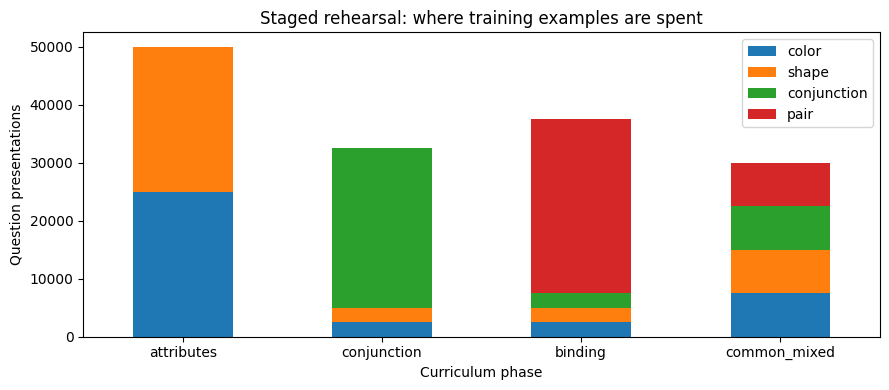

In [2]:
protocol = pd.DataFrame([{
    'seed': r['seed'], 'schedule': r['schedule'], 'updates': r['steps_run'],
    'total_presentations': r['exposure_plan']['total_presentations'],
    'per_example': r['exposure_plan']['repetitions_per_example'],
    **r['exposure_plan']['counts_by_template']
} for r in runs])
display(protocol.groupby('schedule')[['updates', 'total_presentations', 'per_example']]
        .agg(['min', 'max']).reindex(SCHEDULES))
protocol.to_csv(OUTPUT_DIR / 'exposure_by_seed.csv', index=False)

replay = next(r for r in runs if r['schedule'] == 'staged_rehearsal')
phase_exposure = pd.DataFrame([{'phase': p['name'], **{task: p['by_template'].get(task, 0)
                                            for task in TASKS}}
                               for p in replay['exposure_plan']['phase_task_presentations']])
display(phase_exposure)
phase_exposure.to_csv(OUTPUT_DIR / 'rehearsal_phase_exposure.csv', index=False)
fig, ax = plt.subplots(figsize=(9, 4))
phase_exposure.set_index('phase')[list(TASKS)].plot.bar(stacked=True, ax=ax, rot=0)
ax.set(title='Staged rehearsal: where training examples are spent',
       xlabel='Curriculum phase', ylabel='Question presentations')
plt.tight_layout()
save_figure(fig, 'rehearsal_exposure_by_phase')
plt.show()

## 2. Does replay help final binding or generalization?

Compare final ID binding, OOD binding, full ID accuracy, shape recognition and AULC. The main evaluation is at the **common final step**, not each schedule's individually selected best checkpoint. BCE is also shown for OOD; it penalizes high-confidence errors even when accuracy remains unchanged.

overall_id         pair        shape       conjunction        \
                       mean   std   mean   std   mean   std        mean   std   
schedule                                                                        
mixed                 72.44  2.38  53.52  2.59  61.33  1.32       78.12  3.75   
staged                73.20  1.37  55.86  3.63  60.39  1.58       79.14  2.56   
staged_rehearsal      73.59  1.46  55.47  3.24  61.80  1.69       79.30  3.45   
reverse               70.86  2.93  53.59  2.25  59.53  2.40       75.23  5.39   

                 ood_pair       ood_bce       pair_aulc        
                     mean   std    mean   std      mean   std  
schedule                                                       
mixed               54.35  1.76    0.71  0.04     53.00  1.03  
staged              53.30  5.53    0.70  0.03     52.70  0.86  
staged_rehearsal    54.15  2.45    0.71  0.04     53.08  0.97  
reverse             53.35  1.47    0.73  0.05     51.51  0.95

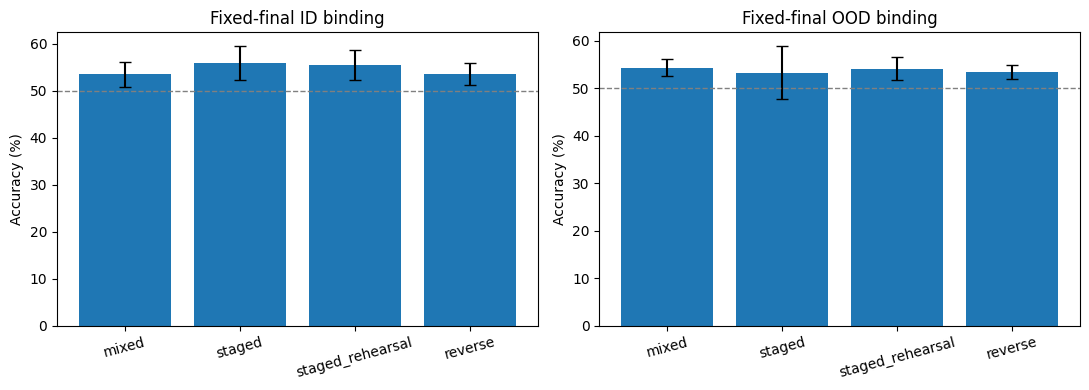

In [3]:
rows = []
for r in runs:
    f = r['final']
    rows.append({
        'seed': r['seed'], 'schedule': r['schedule'],
        'overall_id': 100 * f['id_dev']['accuracy'],
        'ood_pair': 100 * f['ood_dev']['by_template']['pair'],
        'ood_bce': f['ood_dev']['loss'],
        'pair_aulc': 100 * r['id_pair_aulc'],
        'final_lr': f['lr'],
        **{task: 100 * f['id_dev']['by_template'][task] for task in TASKS}
    })
final = pd.DataFrame(rows)
metrics = ['overall_id', 'pair', 'shape', 'conjunction', 'ood_pair', 'ood_bce', 'pair_aulc']
display(final.groupby('schedule')[metrics].agg(['mean', 'std']).reindex(SCHEDULES).round(2))
final.to_csv(OUTPUT_DIR / 'final_by_seed.csv', index=False)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, metric, title in zip(axes, ('pair', 'ood_pair'), ('ID binding', 'OOD binding')):
    agg = final.groupby('schedule')[metric].agg(['mean', 'std']).reindex(SCHEDULES)
    ax.bar(SCHEDULES, agg['mean'], yerr=agg['std'], capsize=4)
    ax.axhline(50, color='gray', linestyle='--', linewidth=1)
    ax.set(title='Fixed-final ' + title, ylabel='Accuracy (%)')
    ax.tick_params(axis='x', rotation=15)
plt.tight_layout()
save_figure(fig, 'final_id_ood_binding')
plt.show()

## 3. What difference does rehearsal make when seeds are paired?

For each seed \(s\), compare the same initialized model under two schedules: \(\Delta_s=A_s(\mathrm{rehearsal})-A_s(\mathrm{control})\). Report the mean difference and how often it is positive. A small mean over five seeds is suggestive, not a statistical guarantee.

,contrast,metric,mean_pp,sd_pp,wins
0,staged_rehearsal − staged,pair,-0.39,1.00,1
1,staged_rehearsal − staged,ood_pair,0.85,3.48,2
2,staged_rehearsal − staged,pair_aulc,0.38,0.37,5
3,staged_rehearsal − staged,overall_id,0.39,0.15,5
4,staged_rehearsal − staged,shape,1.41,0.98,4
5,staged_rehearsal − mixed,pair,1.95,1.07,5
6,staged_rehearsal − mixed,ood_pair,-0.20,3.17,1
7,staged_rehearsal − mixed,pair_aulc,0.08,0.70,1
8,staged_rehearsal − mixed,overall_id,1.15,1.27,4
9,staged_rehearsal − mixed,shape,0.47,2.81,3


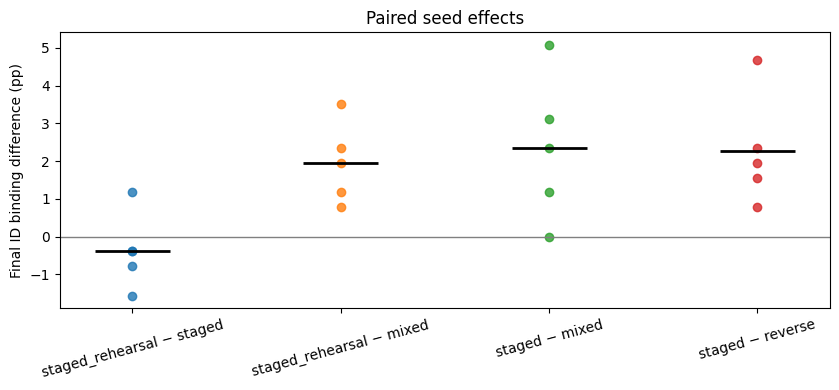

In [4]:
pairs = (('staged_rehearsal', 'staged'), ('staged_rehearsal', 'mixed'),
         ('staged', 'mixed'), ('staged', 'reverse'))
paired = []
for first, second in pairs:
    for metric in ('pair', 'ood_pair', 'pair_aulc', 'overall_id', 'shape'):
        p = final.pivot(index='seed', columns='schedule', values=metric)
        delta = p[first] - p[second]
        paired.append({'contrast': first + ' − ' + second,
                       'metric': metric, 'mean_pp': delta.mean(),
                       'sd_pp': delta.std(), 'wins': int((delta > 0).sum())})
paired = pd.DataFrame(paired)
display(paired.round(2))
paired.to_csv(OUTPUT_DIR / 'paired_differences.csv', index=False)

pair_data = final.pivot(index='seed', columns='schedule', values='pair')
fig, ax = plt.subplots(figsize=(8.5, 4))
for i, (first, second) in enumerate(pairs):
    delta = pair_data[first] - pair_data[second]
    ax.scatter([i]*len(delta), delta, alpha=.8)
    ax.hlines(delta.mean(), i-.18, i+.18, color='black', linewidth=2)
ax.axhline(0, color='gray', linewidth=1)
ax.set(xticks=range(len(pairs)), xticklabels=[f'{a} − {b}' for a,b in pairs],
       ylabel='Final ID binding difference (pp)', title='Paired seed effects')
ax.tick_params(axis='x', rotation=15)
plt.tight_layout()
save_figure(fig, 'paired_binding_differences')
plt.show()

## 4. What does the shared LR trajectory isolate?

Earlier plateau experiments used `ReduceLROnPlateau`, which can lower the LR when the *overall* validation loss stagnates, even if the current curriculum hasn't introduced binding yet. Here every schedule replays the same **mixed-run LR sequence** within each seed (constant \(10^{-4}\) in the recorded reference). The optimizer remains AdamW; only the example sequence differs across schedules. This removes the **realized-LR confound**, although the curriculum still changes the timing and mixture of task exposure.

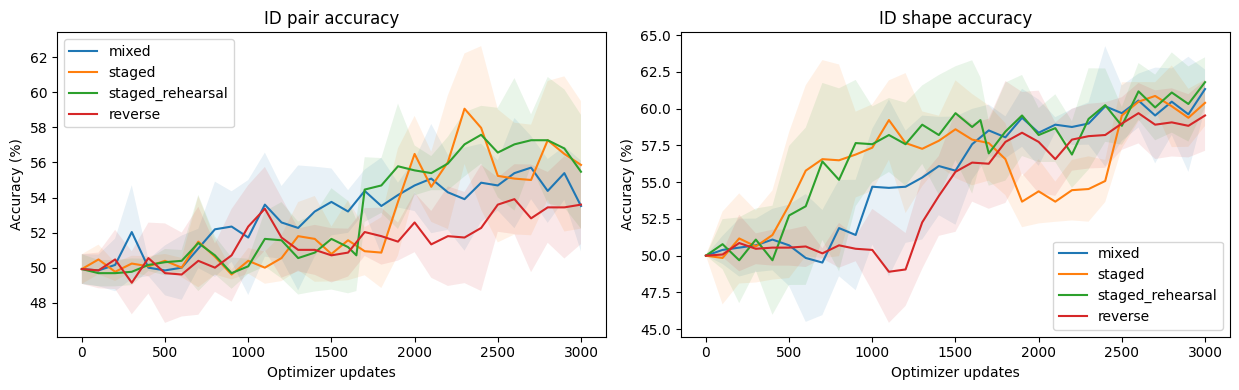

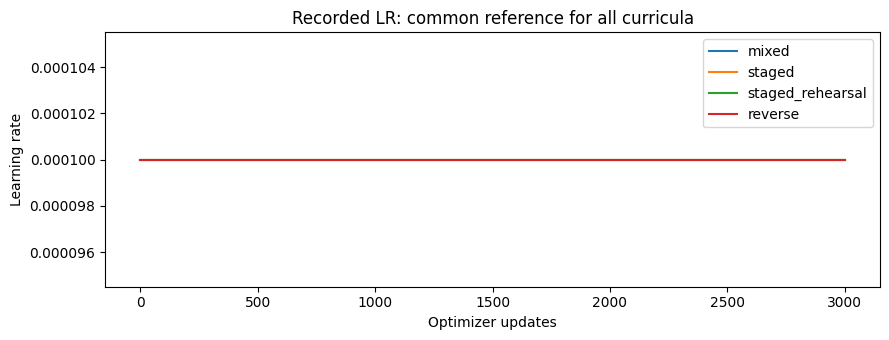

In [5]:
history = pd.DataFrame([{
    'seed': r['seed'], 'schedule': r['schedule'], 'step': h['step'],
    'phase': h['phase'], 'lr': h['lr_after'],
    'id_loss': h['id_dev']['loss'],
    **{task: 100 * h['id_dev']['by_template'][task] for task in TASKS}
} for r in runs for h in r['history']])
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4))
for ax, task in zip(axes, ('pair', 'shape')):
    for schedule in SCHEDULES:
        v = history[history.schedule == schedule].groupby('step')[task].agg(['mean', 'std'])
        ax.plot(v.index, v['mean'], label=schedule)
        ax.fill_between(v.index, v['mean']-v['std'], v['mean']+v['std'], alpha=.1)
    ax.set(title='ID ' + task + ' accuracy', xlabel='Optimizer updates', ylabel='Accuracy (%)')
    ax.legend()
plt.tight_layout()
save_figure(fig, 'binding_and_shape_learning_curves')
plt.show()

fig, ax = plt.subplots(figsize=(9, 3.5))
for schedule in SCHEDULES:
    v = history[history.schedule == schedule].groupby('step')['lr'].mean()
    ax.plot(v.index, v.values, label=schedule)
ax.set(title='Recorded LR: common reference for all curricula',
       xlabel='Optimizer updates', ylabel='Learning rate')
ax.legend()
plt.tight_layout()
save_figure(fig, 'shared_learning_rate')
plt.show()

## 5. Did replay reduce forgetting at the phase switch?

For each run and phase transition, compare task accuracy at the last evaluation of the old phase and the first evaluation of the new phase. The effect combines one more 100-update training interval with a change in task mixture. The key contrast is **staged-rehearsal versus staged without replay**, particularly at conjunction → binding and at common mixed consolidation.

color  shape  conjunction  pair
schedule         transition                                                
mixed            initial → mixed             0.94   0.39        -0.23 -0.08
                 mixed → common_mixed        0.23  -0.47         1.17 -0.16
reverse          attributes → common_mixed   0.39   0.78         0.39  1.33
                 binding → conjunction       3.52  -0.47         2.81  0.78
                 conjunction → attributes    4.53   3.20         1.25 -0.70
                 initial → binding          -0.94   0.08        -0.16 -0.08
staged           attributes → conjunction   -1.88  -0.39         7.73  1.25
                 binding → common_mixed     13.12   4.45        11.56 -2.73
                 conjunction → binding     -12.97  -2.89       -13.05  2.89
                 initial → attributes        0.31  -0.16         0.78  0.55
staged_rehearsal attributes → conjunction    1.02   0.62         7.19  1.56
                 binding → common_mixed      1.25  -1.41         1.56 -1.02
                 conjunction → binding      -1.17  -2.27        -6.72  3.75
                 initial → attributes        1.17   0.78         0.08 -0.23

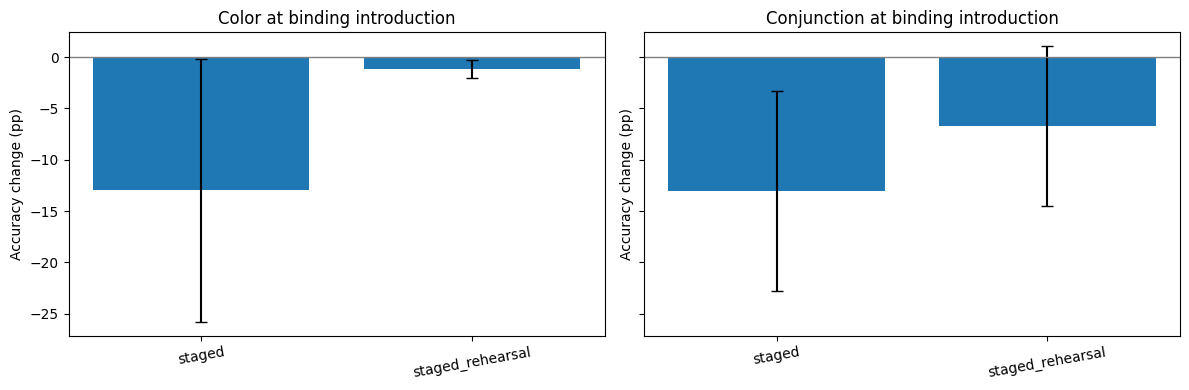

In [6]:
changes = []
for r in runs:
    for old, new in zip(r['history'], r['history'][1:]):
        if old['phase'] == new['phase']:
            continue
        changes.append({
            'seed': r['seed'], 'schedule': r['schedule'],
            'transition': old['phase'] + ' → ' + new['phase'],
            'step_before': old['step'], 'step_after': new['step'],
            **{task: 100 * (new['id_dev']['by_template'][task]
                            - old['id_dev']['by_template'][task]) for task in TASKS}
        })
changes = pd.DataFrame(changes)
changes.to_csv(OUTPUT_DIR / 'transition_changes.csv', index=False)
summary = changes.groupby(['schedule', 'transition'])[list(TASKS)].mean()
display(summary.round(2))

selected = changes[(changes.schedule.isin(('staged', 'staged_rehearsal'))) &
                   (changes.transition == 'conjunction → binding')]
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, task in zip(axes, ('color', 'conjunction')):
    vals = selected.groupby('schedule')[task].agg(['mean', 'std']).reindex(('staged', 'staged_rehearsal'))
    ax.bar(vals.index, vals['mean'], yerr=vals['std'], capsize=4)
    ax.axhline(0, color='gray', linewidth=1)
    ax.set(title=task.title() + ' at binding introduction', ylabel='Accuracy change (pp)')
    ax.tick_params(axis='x', rotation=10)
plt.tight_layout()
save_figure(fig, 'transition_retention_color_conjunction')
plt.show()

## 6. Retention before and after shared consolidation

A curriculum that has not practiced an earlier skill recently may exhibit declining accuracy before the common mixed phase. We compare performance at the last checkpoint in the initial training plan (step 2,400) against the final checkpoint (step 3,000). This shows how **common rehearsal** changes accuracy, not a causal effect of the staged-rehearsal policy alone.

mean    std
schedule         task                     
mixed            color         1.72   2.98
                 conjunction   1.88   1.64
                 pair         -1.33   2.92
                 shape         1.17   3.39
reverse          color         2.27   1.88
                 conjunction   1.02   1.28
                 pair          1.33   4.46
                 shape         1.33   2.57
staged           color        15.16  12.20
                 conjunction  14.38   9.11
                 pair         -2.11   4.85
                 shape         5.31   2.39
staged_rehearsal color         2.11   2.00
                 conjunction   2.66   2.78
                 pair         -2.11   2.30
                 shape         1.56   3.83

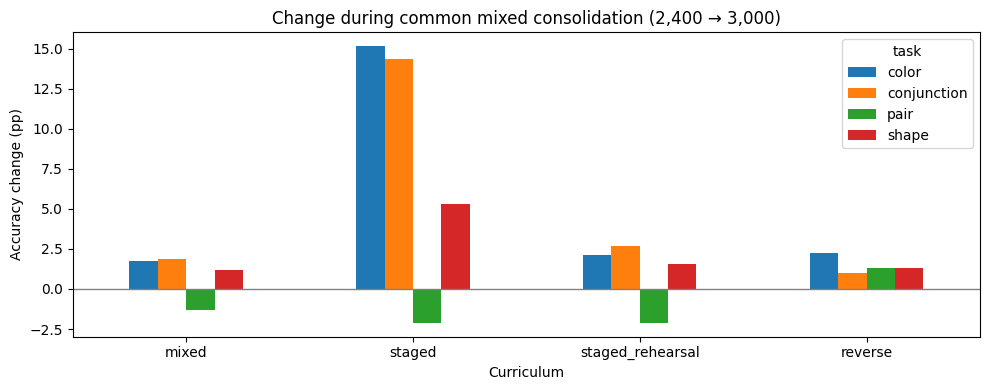

In [7]:
retention = []
for r in runs:
    checkpoints = {h['step']: h for h in r['history']}
    for task in TASKS:
        before = 100 * checkpoints[2400]['id_dev']['by_template'][task]
        after = 100 * checkpoints[3000]['id_dev']['by_template'][task]
        retention.append({
            'seed': r['seed'], 'schedule': r['schedule'], 'task': task,
            'pre_common': before, 'final': after, 'change_pp': after-before
        })
retention = pd.DataFrame(retention)
retention.to_csv(OUTPUT_DIR / 'consolidation_retention.csv', index=False)
display(retention.groupby(['schedule', 'task'])['change_pp'].agg(['mean', 'std']).round(2))
fig, ax = plt.subplots(figsize=(10, 4))
retention.groupby(['schedule', 'task'])['change_pp'].mean().unstack('task').reindex(SCHEDULES).plot.bar(ax=ax, rot=0)
ax.axhline(0, color='gray', linewidth=1)
ax.set(title='Change during common mixed consolidation (2,400 → 3,000)',
       xlabel='Curriculum', ylabel='Accuracy change (pp)')
plt.tight_layout()
save_figure(fig, 'common_consolidation_changes')
plt.show()

## 7. What was actually rehearsed?

Rehearsal substitutes earlier-task examples within a **matched overall exposure budget**; it is not extra data. Visualize the actual allocations rather than assuming equal replay throughout training. This also shows why the rehearsal curriculum has different phase durations than pure staging.

,color,shape,conjunction,pair
phase,,,,
attributes,25000,25000,0,0
conjunction,2500,2500,27500,0
binding,2500,2500,2500,30000
common_mixed,7500,7500,7500,7500


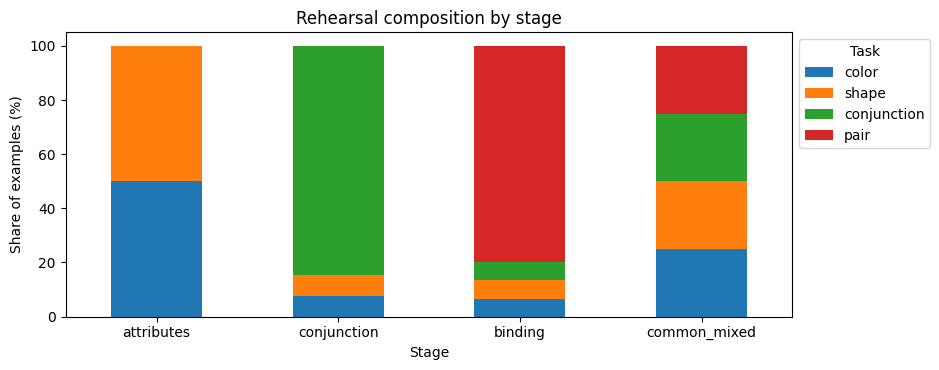

In [8]:
r = next(r for r in runs if r['schedule'] == 'staged_rehearsal')
allocations = pd.DataFrame([{'phase': p['name'], **p['by_template']}
                            for p in r['exposure_plan']['phase_task_presentations']]).fillna(0)
allocations = allocations.set_index('phase').reindex(columns=TASKS, fill_value=0)
display(allocations.astype(int))
fig, ax = plt.subplots(figsize=(9.5, 3.8))
(100 * allocations.div(allocations.sum(axis=1), axis=0)).plot.bar(stacked=True, ax=ax, rot=0)
ax.set(title='Rehearsal composition by stage', ylabel='Share of examples (%)', xlabel='Stage')
ax.legend(title='Task', bbox_to_anchor=(1, 1))
plt.tight_layout()
save_figure(fig, 'rehearsal_task_allocation')
plt.show()
allocations.to_csv(OUTPUT_DIR / 'rehearsal_phase_allocation.csv')

## 8. How do skills evolve *through* a stage?

The matrices below report end-of-stage performance on **all tasks**, not only the currently trained task. Stage gains \(G_{s,k}\) use the last evaluation at or before each stage boundary and reveal incidental transfer and interference; final consolidation reveals which skills recover. The phase durations differ between staged and staged-rehearsal, so the matrices are descriptive rather than time-matched causal comparisons.

accuracy_end  change_pp
schedule         phase        task                                
mixed            common_mixed color               96.80       1.72
                              conjunction         78.12       1.88
                              pair                53.52      -1.33
                              shape               61.33       1.17
                 mixed        color               95.08      43.52
                              conjunction         76.25      26.09
                              pair                54.84       4.92
                              shape               60.16      10.16
reverse          attributes   color               92.81      24.77
                              conjunction         74.22      11.56
                              pair                52.27       0.55
                              shape               58.20       9.14
                 binding      color               50.70      -0.86
                              conjunction         50.78       0.62
                              pair                49.61      -0.31
                              shape               50.62       0.62
                 common_mixed color               95.08       2.27
                              conjunction         75.23       1.02
                              pair                53.59       1.33
                              shape               59.53       1.33
                 conjunction  color               68.05      17.34
                              conjunction         62.66      11.88
                              pair                51.72       2.11
                              shape               49.06      -1.56
staged           attributes   color               91.64      40.08
                              conjunction         67.81      17.66
                              pair                50.55       0.62
                              shape               57.66       7.66
                 binding      color               82.27     -12.19
                              conjunction         64.77     -12.58
                              pair                57.97       7.11
                              shape               55.08      -1.48
                 common_mixed color               97.42      15.16
                              conjunction         79.14      14.38
                              pair                55.86      -2.11
                              shape               60.39       5.31
                 conjunction  color               94.45       2.81
                              conjunction         77.34       9.53
                              pair                50.86       0.31
                              shape               56.56      -1.09
staged_rehearsal attributes   color               87.66      36.09
                              conjunction         65.55      15.39
                              pair                50.08       0.16
                              shape               57.58       7.58
                 binding      color               95.70       0.39
                              conjunction         76.64      -1.09
                              pair                57.58       6.88
                              shape               60.23       1.02
                 common_mixed color               97.81       2.11
                              conjunction         79.30       2.66
                              pair                55.47      -2.11
                              shape               61.80       1.56
                 conjunction  color               95.31       7.66
                              conjunction         77.73      12.19
                              pair                50.70       0.62
                              shape               59.22       1.64

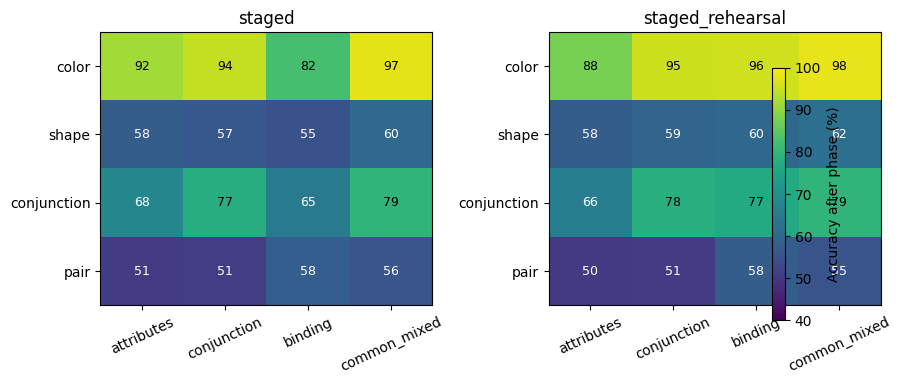

In [9]:
phase_rows = []
for r in runs:
    snapshots = {h['step']: h for h in r['history']}
    start = 0
    for item in r['exposure_plan']['phases']:
        end = start + item['presentations'] // report['config']['batch_size']
        observed_end = max(t for t in snapshots if t <= end)
        observed_start = max(t for t in snapshots if t <= start)
        for task in TASKS:
            before = 100 * snapshots[observed_start]['id_dev']['by_template'][task]
            after = 100 * snapshots[observed_end]['id_dev']['by_template'][task]
            phase_rows.append({'seed': r['seed'], 'schedule': r['schedule'],
                               'phase': item['name'], 'start': start, 'end': end,
                               'observed_start': observed_start,
                               'observed_end': observed_end,
                               'task': task, 'accuracy_start': before,
                               'accuracy_end': after, 'change_pp': after - before})
        start = end
phase_scores = pd.DataFrame(phase_rows)
phase_scores.to_csv(OUTPUT_DIR / 'phase_skill_changes.csv', index=False)
display(phase_scores.groupby(['schedule', 'phase', 'task'])[['accuracy_end', 'change_pp']].mean().round(2))
HEAT_SCHEDULES = ('staged', 'staged_rehearsal')
fig, axes = plt.subplots(1, len(HEAT_SCHEDULES), figsize=(5.1 * len(HEAT_SCHEDULES), 4.2))
for ax, schedule in zip(np.atleast_1d(axes), HEAT_SCHEDULES):
    frame = phase_scores[phase_scores.schedule == schedule]
    table = frame.groupby(['task', 'phase'])['accuracy_end'].mean().unstack('phase')
    order = list(dict.fromkeys(frame[frame.seed == frame.seed.min()]['phase']))
    table = table.reindex(index=TASKS, columns=order)
    im = ax.imshow(table, vmin=40, vmax=100, cmap='viridis', aspect='auto')
    ax.set(yticks=range(len(TASKS)), yticklabels=TASKS,
           xticks=range(len(order)), xticklabels=order, title=schedule)
    ax.tick_params(axis='x', rotation=25)
    for i in range(len(TASKS)):
        for j in range(len(order)):
            ax.text(j, i, f'{table.iloc[i, j]:.0f}', ha='center', va='center',
                    fontsize=9, color='white' if table.iloc[i, j] < 68 else 'black')
fig.colorbar(im, ax=np.atleast_1d(axes).tolist(), label='Accuracy after phase (%)', shrink=.78)
fig.subplots_adjust(wspace=.35, bottom=.23, right=.89)
save_figure(fig, 'phase_skill_matrices')
plt.show()

## 9. Does rehearsal prevent sustained forgetting?

Measure three quantities during the binding phase: the first 100-update change, the **worst** drop from the pre-binding checkpoint, and end-of-stage retention. Also measure the subsequent mixed-phase recovery. This distinguishes a short dip from prolonged loss of prerequisite skills.

In [10]:
FORGET_SCHEDULES = ('staged', 'staged_rehearsal')
forget_rows = []
for r in runs:
    if r['schedule'] not in FORGET_SCHEDULES:
        continue
    plan = r['exposure_plan']['phases']
    start = sum(p['presentations'] for p in plan[:next(i for i, p in enumerate(plan)
                 if p['name'] == 'binding')]) // report['config']['batch_size']
    end = start + next(p['presentations'] for p in plan if p['name'] == 'binding') // report['config']['batch_size']
    hist = {h['step']: h for h in r['history']}
    pre_binding = max(t for t in hist if t <= start)
    observed_end = max(t for t in hist if t <= end)
    during = [h for h in r['history'] if start < h['step'] <= end]
    for task in ('color', 'shape', 'conjunction'):
        before = 100 * hist[pre_binding]['id_dev']['by_template'][task]
        values = [100 * h['id_dev']['by_template'][task] for h in during]
        at_end = 100 * hist[observed_end]['id_dev']['by_template'][task]
        at_final = 100 * r['final']['id_dev']['by_template'][task]
        forget_rows.append({'seed': r['seed'], 'schedule': r['schedule'],
                            'task': task, 'binding_start': start, 'binding_end': end,
                            'change_first_100': values[0] - before,
                            'max_drop_pp': max(0, before - min(values)),
                            'change_binding_stage': at_end - before,
                            'recovery_after_binding': at_final - at_end})
forgetting = pd.DataFrame(forget_rows)
forgetting.to_csv(OUTPUT_DIR / 'binding_forgetting_recovery.csv', index=False)
display(forgetting.groupby(['schedule', 'task'])
        [['change_first_100', 'max_drop_pp', 'change_binding_stage',
          'recovery_after_binding']].agg(['mean', 'std']).round(2))

change_first_100        max_drop_pp         \
                                         mean    std        mean    std   
schedule         task                                                     
staged           color                 -12.97  12.83       15.94  14.89   
                 conjunction           -13.05   9.73       16.09  10.89   
                 shape                  -2.89   1.40        3.91   2.14   
staged_rehearsal color                  -1.17   0.87        1.17   0.87   
                 conjunction            -6.72   7.80        6.88   7.70   
                 shape                  -2.27   1.31        3.36   2.06   

                             change_binding_stage         \
                                             mean    std   
schedule         task                                      
staged           color                     -12.19  11.28   
                 conjunction               -12.58  10.34   
                 shape                      -1.48   3.15   
staged_rehearsal color                       0.39   1.44   
                 conjunction                -1.09   2.30   
                 shape                       1.02   1.37   

                             recovery_after_binding         
                                               mean    std  
schedule         task                                       
staged           color                        15.16  12.20  
                 conjunction                  14.38   9.11  
                 shape                         5.31   2.39  
staged_rehearsal color                         2.11   2.00  
                 conjunction                   2.66   2.78  
                 shape                         1.56   3.83

## 10. Do earlier skills survive as binding improves?

At a shared global update, compare mean color, conjunction and binding accuracy. Rehearsal may improve retention while reducing the time devoted to new binding examples. This plot shows the trade-off directly rather than relying on final binding alone.

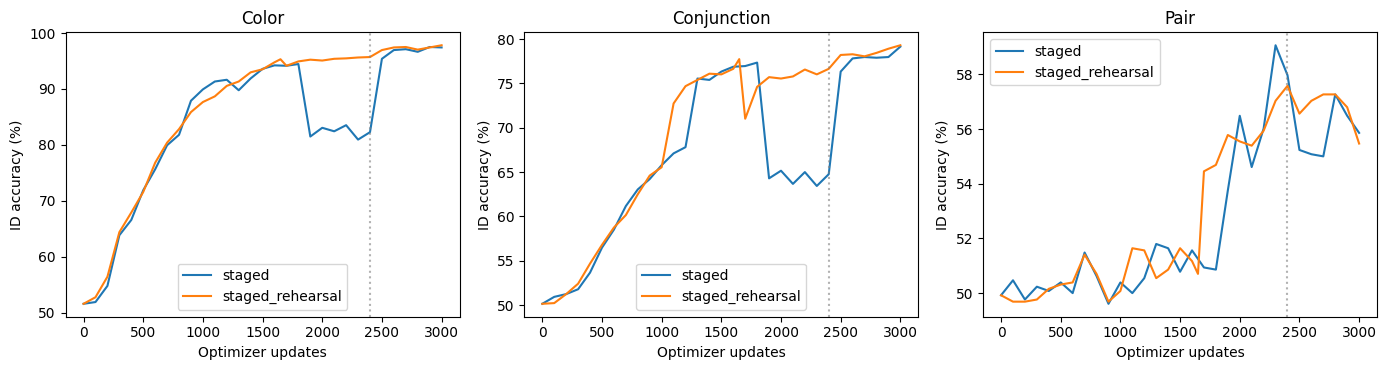

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8), sharex=True)
for ax, task in zip(axes, ('color', 'conjunction', 'pair')):
    for schedule in ('staged', 'staged_rehearsal'):
        v = history[history.schedule == schedule].groupby('step')[task].mean()
        ax.plot(v.index, v.values, label=schedule)
    ax.axvline(2400, linestyle=':', color='gray', alpha=.6)
    ax.set(title=task.title(), xlabel='Optimizer updates', ylabel='ID accuracy (%)')
    ax.legend()
plt.tight_layout()
save_figure(fig, 'retention_binding_tradeoff_trajectories')
plt.show()

## Reading the evidence

With the same seeds, example counts, final step and LR sequence, this experiment better isolates the influence of **training-order and replay allocation**. It does **not** isolate replay itself from changed phase lengths, nor does it establish compositional generalization from modest ID binding gains. Examine retention and OOD binding together, not only final ID accuracy.